In [1]:
!pip install kagglehub
!pip install opencv-python

In [2]:
import kagglehub
path = kagglehub.dataset_download("techsash/waste-classification-data")

In [3]:
import cv2
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
import os
print("Current Directory:", os.getcwd())

# List files and folders in the dataset directory
dataset_path = "DATASET" 
print("Contents:", os.listdir(dataset_path))

Current Directory: C:\Users\aluar\Downloads\waste-cnn+vgg
Contents: ['TEST', 'TRAIN']


In [5]:
import glob
from PIL import Image
import matplotlib.image as mpimg

In [6]:
O_img = [{'O': cv2.imread(file)} for file in glob.glob("DATASET/TRAIN/O/*.jpg")]

In [40]:
O_img = [{'O': cv2.cvtColor(O_img[i]['O'], cv2.COLOR_BGR2RGB)} for i in range(len(O_img))]

In [8]:
R_img = [{'R': cv2.imread(file)} for file in glob.glob("DATASET/TRAIN/R/*.jpg")]

In [9]:
R_img = [{'R': cv2.cvtColor(R_img[i]['R'], cv2.COLOR_BGR2RGB)} for i in range(len(R_img))]

In [10]:
train_img = O_img + R_img

In [11]:
import random
fig = plt.figure(figsize=(20,20))
for i, img in enumerate(random.choices(train_img, k=25), 1):
    #print(i, img)
    for key, val in img.items():
        #print(key)
        if key == 'R':
            ax = fig.add_subplot(5,5,i)
            #print(val)
            plt.title('R')
            ax.imshow(val)
        elif key == 'O':
            ax = fig.add_subplot(5,5,i)
            #print(l)
            plt.title('O')
            ax.imshow(val)
        #mpplot.show()

In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [13]:
image_gen = ImageDataGenerator(rotation_range=30, 
                               width_shift_range=0.1, 
                               height_shift_range=0.1, 
                               rescale=1/255, 
                               shear_range=0.2, 
                               zoom_range=0.2, 
                               horizontal_flip=True, 
                               fill_mode='nearest' 
                              )

In [14]:
#Width, Height, Channels
image_shape = (150, 150, 3)

In [15]:
from keras.models import Sequential
from keras.layers import Activation, Dropout, Flatten, Dense, Conv2D, MaxPooling2D, BatchNormalization
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout
import tensorflow as tf

model = Sequential()

# First Conv2D layer (only this one should have input_shape)
model.add(Conv2D(filters=32, kernel_size=(3,3), input_shape=(150,150,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Second Conv2D layer 
model.add(Conv2D(filters=64, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Third Conv2D layer 
model.add(Conv2D(filters=64, kernel_size=(3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Flatten()) # Flatten, and add a fully connected layer

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))  # Dropout 50% of the previous layer during training

# Output layer for binary classification 
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy',
              optimizer='adam',
               metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])



C:\Users\aluar\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,367,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,424,065 (9.25 MB)

 Trainable params: 2,424,065 (9.25 MB)

 Non-trainable params: 0 (0.00 B)

training

In [19]:
batch_size = 16

train_image_gen = image_gen.flow_from_directory('DATASET/TRAIN',
                                               target_size=image_shape[:2],
                                               batch_size=batch_size,
                                               class_mode='binary')

Found 22564 images belonging to 2 classes.


In [20]:
batch_size = 16

test_image_gen = image_gen.flow_from_directory('DATASET/TEST',
                                               target_size=image_shape[:2],
                                               batch_size=batch_size,
                                               class_mode='binary')

Found 2512 images belonging to 2 classes.


In [21]:
train_image_gen.class_indices

{'O': 0, 'R': 1}

In [22]:
import warnings
warnings.filterwarnings('ignore')

In [23]:
results = model.fit(
    train_image_gen,  # Training data generator
    epochs=100,
    steps_per_epoch=150,
    validation_data=test_image_gen,  # Validation data generator
    validation_steps=12
)

Epoch 1/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 102s 648ms/step - accuracy: 0.6618 - loss: 0.6051 - precision: 0.6174 - recall: 0.5307 - val_accuracy: 0.8490 - val_loss: 0.3993 - val_precision: 0.9077 - val_recall: 0.7195
Epoch 2/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 87s 585ms/step - accuracy: 0.7731 - loss: 0.5052 - precision: 0.7463 - recall: 0.7124 - val_accuracy: 0.8490 - val_loss: 0.4191 - val_precision: 0.9516 - val_recall: 0.6941
Epoch 3/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 78s 519ms/step - accuracy: 0.7972 - loss: 0.4523 - precision: 0.7890 - recall: 0.7301 - val_accuracy: 0.8229 - val_loss: 0.3938 - val_precision: 0.8710 - val_recall: 0.6750
Epoch 4/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 75s 505ms/step - accuracy: 0.8132 - loss: 0.4541 - precision: 0.8250 - recall: 0.7340 - val_accuracy: 0.8021 - val_loss: 0.4519 - val_precision: 0.9254 - val_recall: 0.6526
Epoch 5/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 71s 475ms/step - accuracy: 0.7987 - loss: 0.4708 - precision: 0.8198 - recall: 0.7250 - val_accuracy: 

In [24]:
model.save('wsCNNver.h5')

accuracy table

In [26]:
results.history['accuracy']

[0.7365996837615967,
 0.7799999713897705,
 0.7887499928474426,
 0.8066666722297668,
 0.8149999976158142,
 0.7933333516120911,
 0.8104166388511658,
 0.8170833587646484,
 0.8237500190734863,
 0.8401639461517334,
 0.82791668176651,
 0.8187500238418579,
 0.8229166865348816,
 0.8149999976158142,
 0.8199999928474426,
 0.839614748954773,
 0.8341666460037231,
 0.8391666412353516,
 0.8366666436195374,
 0.8637295365333557,
 0.8512499928474426,
 0.8379166722297668,
 0.8513400554656982,
 0.8320833444595337,
 0.8324999809265137,
 0.8554166555404663,
 0.8500000238418579,
 0.8345833420753479,
 0.8516666889190674,
 0.8524590134620667,
 0.872083306312561,
 0.840833306312561,
 0.8525000214576721,
 0.8495833277702332,
 0.8487499952316284,
 0.8575000166893005,
 0.8533333539962769,
 0.8504166603088379,
 0.8587499856948853,
 0.8350622653961182,
 0.8495833277702332,
 0.8579166531562805,
 0.8558333516120911,
 0.8521775603294373,
 0.85958331823349,
 0.8399999737739563,
 0.8479166626930237,
 0.8583333492279053,

In [27]:
plt.plot(results.history['accuracy'])

testing

In [29]:
import numpy as np
from keras.preprocessing import image

R_file = 'DATASET/TEST/R/R_10147.jpg'

R_test = image.load_img(R_file, target_size=(150, 150))

R_test = image.img_to_array(R_test)

R_test = np.expand_dims(R_test, axis=0)

R_test = R_test/255

In [30]:
prediction_prob = model.predict(R_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step


In [31]:
R_test = R_test.reshape(150,150,3)
plt.imshow(R_test)

In [32]:
print(f'R Probability {prediction_prob}  ')

R Probability [[0.90844685]]  


In [100]:
from sklearn.metrics import confusion_matrix

test_dir = 'DATASET/TEST/' 

test_datagen = ImageDataGenerator(rescale=1./255)  
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(150, 150),  
    batch_size=32,
    class_mode='binary',  
    shuffle=False  
)

y_true = test_generator.classes  

Found 2512 images belonging to 2 classes.


In [102]:
predictions = model.predict(test_generator) 
y_pred = (predictions > 0.5).astype(int).flatten()  


79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 132ms/step


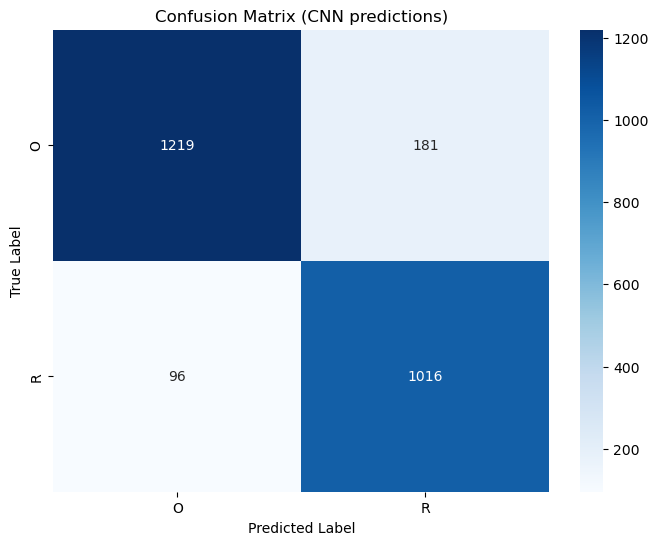

In [104]:
cm = confusion_matrix(y_true, y_pred)

class_labels = ['O', 'R'] 

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (CNN predictions)")
plt.show()
